# Semantic search for yoga poses — retrieve, then rerank

**Goal.** Given a photo of a yoga pose, return the most similar poses from a labelled database,
using **pre-trained CNN embeddings** in a **Qdrant** vector database with a **reranker** on top.

```
query photo ─► frozen CNNs ─► GeM + flip-TTA ─► LDA projection ─► Qdrant top-fetch_k ─► neighbourhood reranker ─► top-k
query text  ─► CLIP text encoder ──────────────────────────────► Qdrant ("clip" vector) ─────────────────────► top-k
```

This notebook walks through the pipeline stage by stage. Every stage lives in `src/` and is run by
`run_pipeline.py` from `config.yaml`; here we call the same functions and analyse their outputs.
Heavy stages are cached in `data/` — set `RECOMPUTE = True` to rebuild them.

### Assumptions
* **Relevance = same pose label** (strict: a visually similar sibling pose counts as wrong).
* **The database is labelled** (like a catalogue), so a linear projection may be learned on the
  gallery images. The CNNs themselves stay frozen.
* **No test-set peeking.** Every choice — embedding configuration and reranker settings — is made on
  the validation split; the test split is scored once, through Qdrant.

In [1]:
import sys

sys.path.insert(0, "..")  # repo root, so `src` imports work from notebooks/

import json

import pandas as pd
from IPython.display import Image, display

from src.data.manifest import load_manifest
from src.data.pose_names import pose_names
from src.utils.config_loader import get_path, load_config

RECOMPUTE = False  # True → rerun data prep, embedding, tuning, indexing and evaluation
config = load_config()
METRICS = get_path(config, "output_dir") / "metrics"
FIG = get_path(config, "output_dir") / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 70)

if RECOMPUTE:
    import run_pipeline as rp

    for stage in ("run_data_prep", "run_embedding", "run_tuning", "run_indexing", "run_retrieval_eval"):
        rp.STAGES[stage](config)

## 1. Data — clean, de-duplicate, split

`src/data/cleaning.py` hashes every file and drops images whose identical bytes are filed under two
different poses (ambiguous label), within-pose duplicates and tiny images; `src/data/splitting.py`
re-splits 70 / 15 / 15 by pose into **gallery** (indexed), **val** (tuning queries) and **test**.

In [2]:
display(pd.Series(json.loads((METRICS / "data_cleaning.json").read_text()), name="images").to_frame().T)
df = load_manifest(config)
per_pose = df.groupby("pose").size()
print(df.split.value_counts().to_string())
print(f"\nimages per pose: min {per_pose.min()}, median {per_pose.median():.0f}, max {per_pose.max()}")

,files_seen,unreadable,too_small,duplicate_within_pose,ambiguous_label,kept
images,5994,0,29,14,177,5774


split
gallery    4041
test        867
val         866

images per pose: min 18, median 55, max 87


## 2. Embeddings and tuning (validation split)

Five frozen networks (`src/embedding/backbones.py`) × pooling (GAP / GeM / CLIP attention) ×
preprocessing (crop / letterbox) × flip-TTA × post-processing (L2 / PCA-whitening / LDA) —
**176 configurations**, each scored by querying val images against the gallery.

176 configurations


,backbone,pooling,preprocess,tta,post,dim,P@1,P@5,P@10,mAP@10,Hit@5
0,ensemble,mixed,pad,True,lda0.1,106,0.678,0.610,0.577,0.499,0.849
1,ensemble,mixed,pad,True,lda0.3,106,0.665,0.603,0.566,0.487,0.861
2,ensemble,mixed,pad,False,lda0.1,106,0.664,0.594,0.557,0.479,0.859
3,ensemble,mixed,pad,False,lda0.3,106,0.665,0.581,0.549,0.470,0.848
4,clip_rn50,gem,pad,True,lda0.1,106,0.634,0.589,0.554,0.469,0.850
5,clip_rn50,gem,pad,True,lda0.3,106,0.644,0.584,0.551,0.466,0.851
6,clip_rn50,gap,pad,True,lda0.1,106,0.620,0.572,0.537,0.456,0.828
7,clip_rn50,gap,pad,True,lda0.3,106,0.627,0.566,0.530,0.448,0.821


,backbone,pooling,preprocess,tta,post,dim,P@1,P@5,P@10,mAP@10,setting
0,ensemble,mixed,pad,True,pcaw256,256,0.398,0.258,0.210,0.142,unsupervised
1,resnet50,gem,crop,True,l2,2048,0.375,0.236,0.182,0.121,unsupervised
2,clip_rn50,gem,pad,True,pcaw256,256,0.345,0.218,0.176,0.114,unsupervised
3,convnext_tiny,gap,crop,True,pcaw256,256,0.349,0.201,0.156,0.100,unsupervised
4,efficientnet_v2_s,gem,pad,True,pcaw256,256,0.329,0.189,0.147,0.092,unsupervised
5,clip_vit_b32,attn,pad,True,pcaw256,256,0.288,0.173,0.137,0.083,unsupervised
6,ensemble,mixed,pad,True,lda0.1,106,0.678,0.610,0.577,0.499,+ LDA
7,clip_rn50,gem,pad,True,lda0.1,106,0.634,0.589,0.554,0.469,+ LDA
8,resnet50,gem,pad,True,lda0.3,106,0.582,0.517,0.483,0.402,+ LDA
9,clip_vit_b32,attn,pad,True,lda0.3,106,0.565,0.493,0.457,0.369,+ LDA


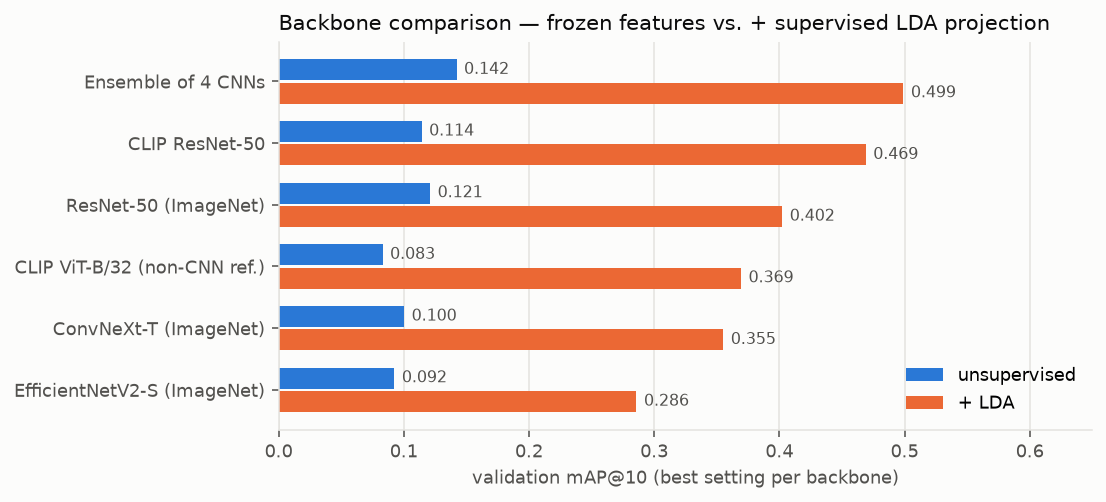

In [3]:
grid = pd.read_csv(METRICS / "tuning_grid_val.csv")
print(len(grid), "configurations")
display(grid.head(8))
display(pd.read_csv(METRICS / "tuning_best_per_backbone_val.csv"))
display(Image(FIG / "search_backbones.png"))

,step,config,P@1,P@5,P@10,mAP@10
0,"ResNet-50, GAP, centre-crop (ImageNet default)",resnet50|gap|crop|single|l2,0.337,0.183,0.141,0.089
1,+ letterbox instead of crop,resnet50|gap|pad|single|l2,0.322,0.184,0.142,0.087
2,+ horizontal-flip TTA,resnet50|gap|pad|tta|l2,0.338,0.191,0.148,0.091
3,+ GeM pooling,resnet50|gem|pad|tta|l2,0.401,0.238,0.183,0.121
4,+ PCA-whitening (256-d),resnet50|gem|pad|tta|pcaw256,0.382,0.230,0.183,0.120
5,+ LDA projection instead (supervised),resnet50|gem|pad|tta|lda0.1,0.562,0.513,0.479,0.399
6,"backbone → CLIP-RN50 (GeM, LDA)",clip_rn50|gem|pad|tta|lda0.1,0.634,0.589,0.554,0.469
7,backbone → ensemble of 4 CNNs (LDA),ensemble|mixed|pad|tta|lda0.1,0.678,0.610,0.577,0.499


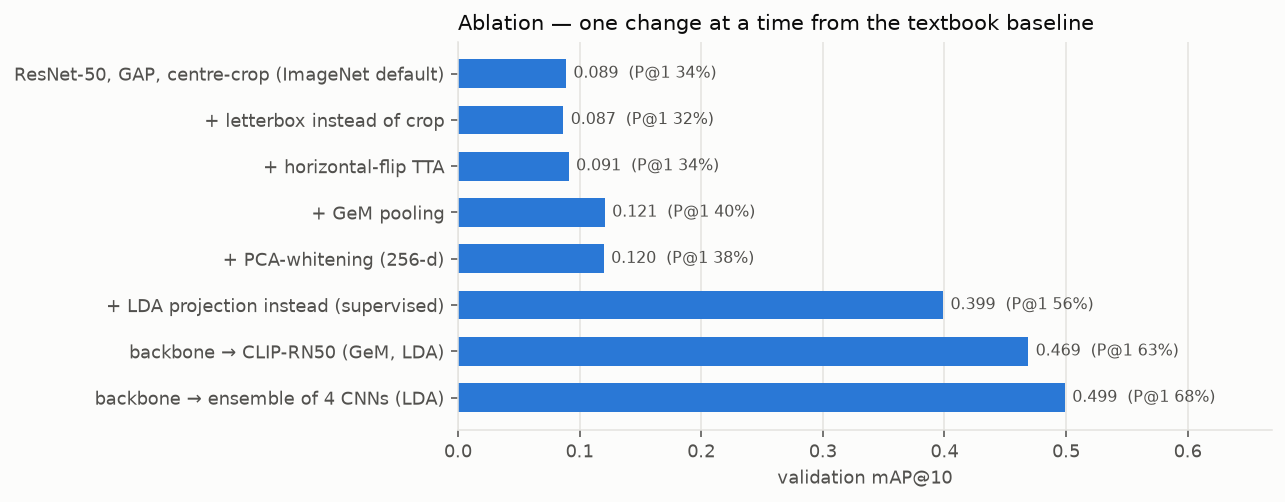

In [4]:
display(pd.read_csv(METRICS / "tuning_ablation_val.csv"))
display(Image(FIG / "search_ablation.png"))

**Reading the tuning results.**
* Frozen descriptors find photos that *look* alike (clothing, background) — every backbone scores
  mAP@10 ≤ 0.14 without a projection. GeM pooling is the best unsupervised change (+33 % for ResNet-50).
* A **shrinkage-LDA projection** learned on the gallery labels multiplies mAP by 3–4.5× for every
  backbone: the pose information is in the features, just not the dominant direction.
* Letterboxing beats centre-crop once LDA is applied (ensemble 0.446 → 0.499) — cropping cuts off
  the hands and feet that define a pose. CLIP-RN50 is the best single CNN; concatenating four CNNs
  is best overall and is selected.

## 3. Indexing — Qdrant

Every image becomes one point with two named vectors — `image` (106-d tuned) and `clip` (1024-d,
for text) — and a payload (`path`, `pose`, `split`). A gallery-neighbour table for the reranker is
saved next to the index.

In [5]:
print((METRICS / "index_meta.json").read_text())

{
  "config": "ensemble|mixed|pad|tta|lda0.1",
  "points": 5774,
  "dims": {
    "image": 106,
    "clip": 1024
  },
  "build_seconds": 3.2
}


## 4. Second stage — the reranker

Dense retrieval scores each gallery image independently. The **neighbourhood reranker**
(`src/retrieval/reranker.py`) rescores the top `fetch_k` candidates by how much each candidate's own
nearest gallery neighbours overlap with the query's: `score = (1 − λ)·cosine + λ·overlap`.

Its settings are tuned on val with a **guardrail**: maximise mAP@10, but Hit@5 (≥ 1 correct pose in
the top 5) may fall by at most 2 points — at high λ the reranker commits to the dominant cluster, and
when that cluster is the wrong pose the user sees no correct result at all.

{'params': {'fetch_k': 20, 'k': 30, 'weight': 0.3}, 'val_metrics': {'P@1': 0.6963048498845266, 'P@5': 0.6452655889145495, 'P@10': 0.6214780600461894, 'mAP@10': 0.5649101873235822, 'Hit@5': 0.8290993071593533}}


,fetch_k,k,weight,P@1,P@5,P@10,mAP@10,Hit@5
0,50,30,0.7,0.674,0.643,0.632,0.586,0.784
1,100,30,0.7,0.673,0.642,0.630,0.585,0.779
2,100,20,0.7,0.665,0.642,0.632,0.585,0.783
3,50,20,0.7,0.666,0.644,0.631,0.584,0.790
4,100,30,0.5,0.680,0.647,0.632,0.582,0.803
5,100,20,0.5,0.677,0.648,0.631,0.582,0.800
6,50,30,0.5,0.680,0.647,0.632,0.582,0.804
7,50,20,0.5,0.677,0.649,0.630,0.581,0.801


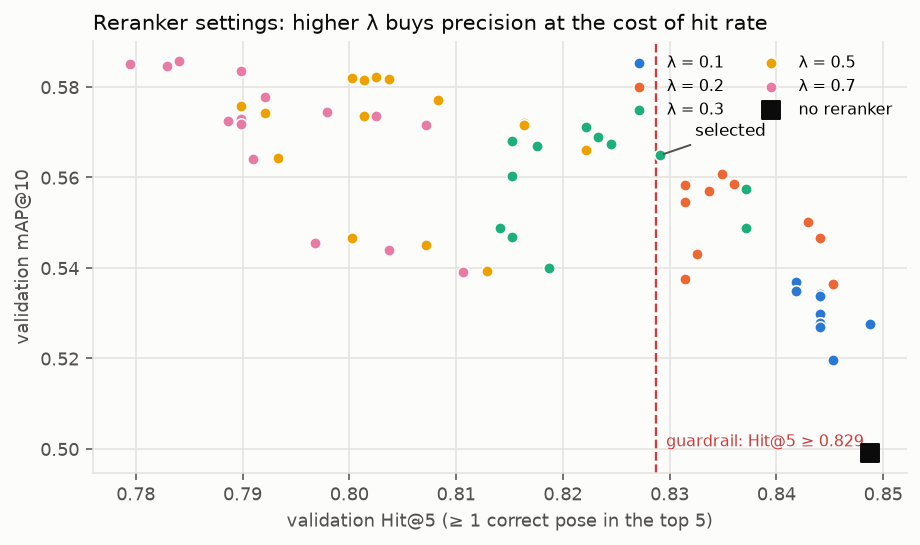

In [6]:
rr = pd.read_csv(METRICS / "reranker_grid_val.csv")
print(json.loads((METRICS / "selected_reranker.json").read_text()))
display(rr.head(8))
display(Image(FIG / "reranker_tradeoff.png"))

,method,P@1,P@5,P@10,mAP@10,Hit@5
0,dense retrieval only (baseline),0.678,0.610,0.577,0.499,0.849
1,"hybrid: tuned + raw CLIP, fused with RRF",0.548,0.418,0.353,0.254,0.806
2,α-query expansion (k=3),0.682,0.630,0.614,0.548,0.834
3,α-query expansion (k=10),0.685,0.633,0.611,0.549,0.820
4,"neighbourhood reranker (fetch_k=20, k=30, λ=0.3)",0.696,0.645,0.621,0.565,0.829


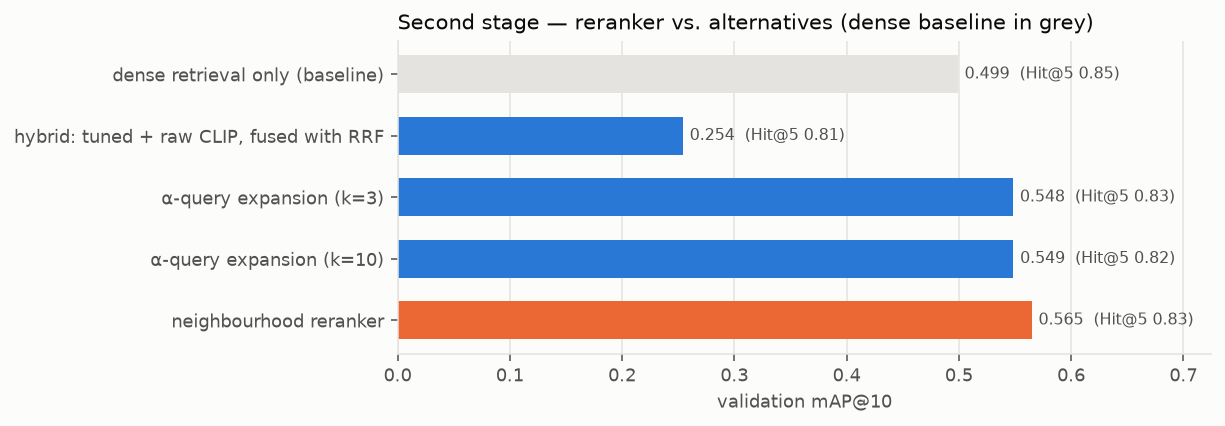

In [7]:
display(pd.read_csv(METRICS / "reranker_alternatives_val.csv"))
display(Image(FIG / "reranker_alternatives.png"))

**Why hybrid RRF fails here** although it is standard in text RAG: BM25 and dense retrieval are
both decent and make *different* mistakes, whereas raw CLIP vectors are far weaker than the tuned
vector (mAP 0.12 vs. 0.50). RRF gives both lists an equal vote, so it mostly imports CLIP's errors.
α-query expansion helps; the neighbourhood reranker helps most.

## 5. Final evaluation — held-out test split, through Qdrant

Test images query the real index (`split == "gallery"` filter). The validation numbers reproduced
through Qdrant equal the offline grid-search numbers — the served pipeline is the evaluated one.

In [8]:
final = json.loads((METRICS / "retrieval_final.json").read_text())
table = pd.DataFrame(
    {f"{split} · {stage}": final[split][stage] for split in ("val", "test") for stage in ("dense", "dense+rerank")}
).T
display(table)
print("latency per query (ms):", {k: round(v, 3) for k, v in final["test"]["ms_per_query"].items()})

,P@1,P@5,P@10,mAP@10,Hit@5
val · dense,0.678,0.610,0.577,0.499,0.849
val · dense+rerank,0.696,0.645,0.621,0.565,0.829
test · dense,0.697,0.628,0.601,0.525,0.870
test · dense+rerank,0.706,0.656,0.643,0.584,0.849


latency per query (ms): {'vector_db': 20.651, 'rerank': 0.022}


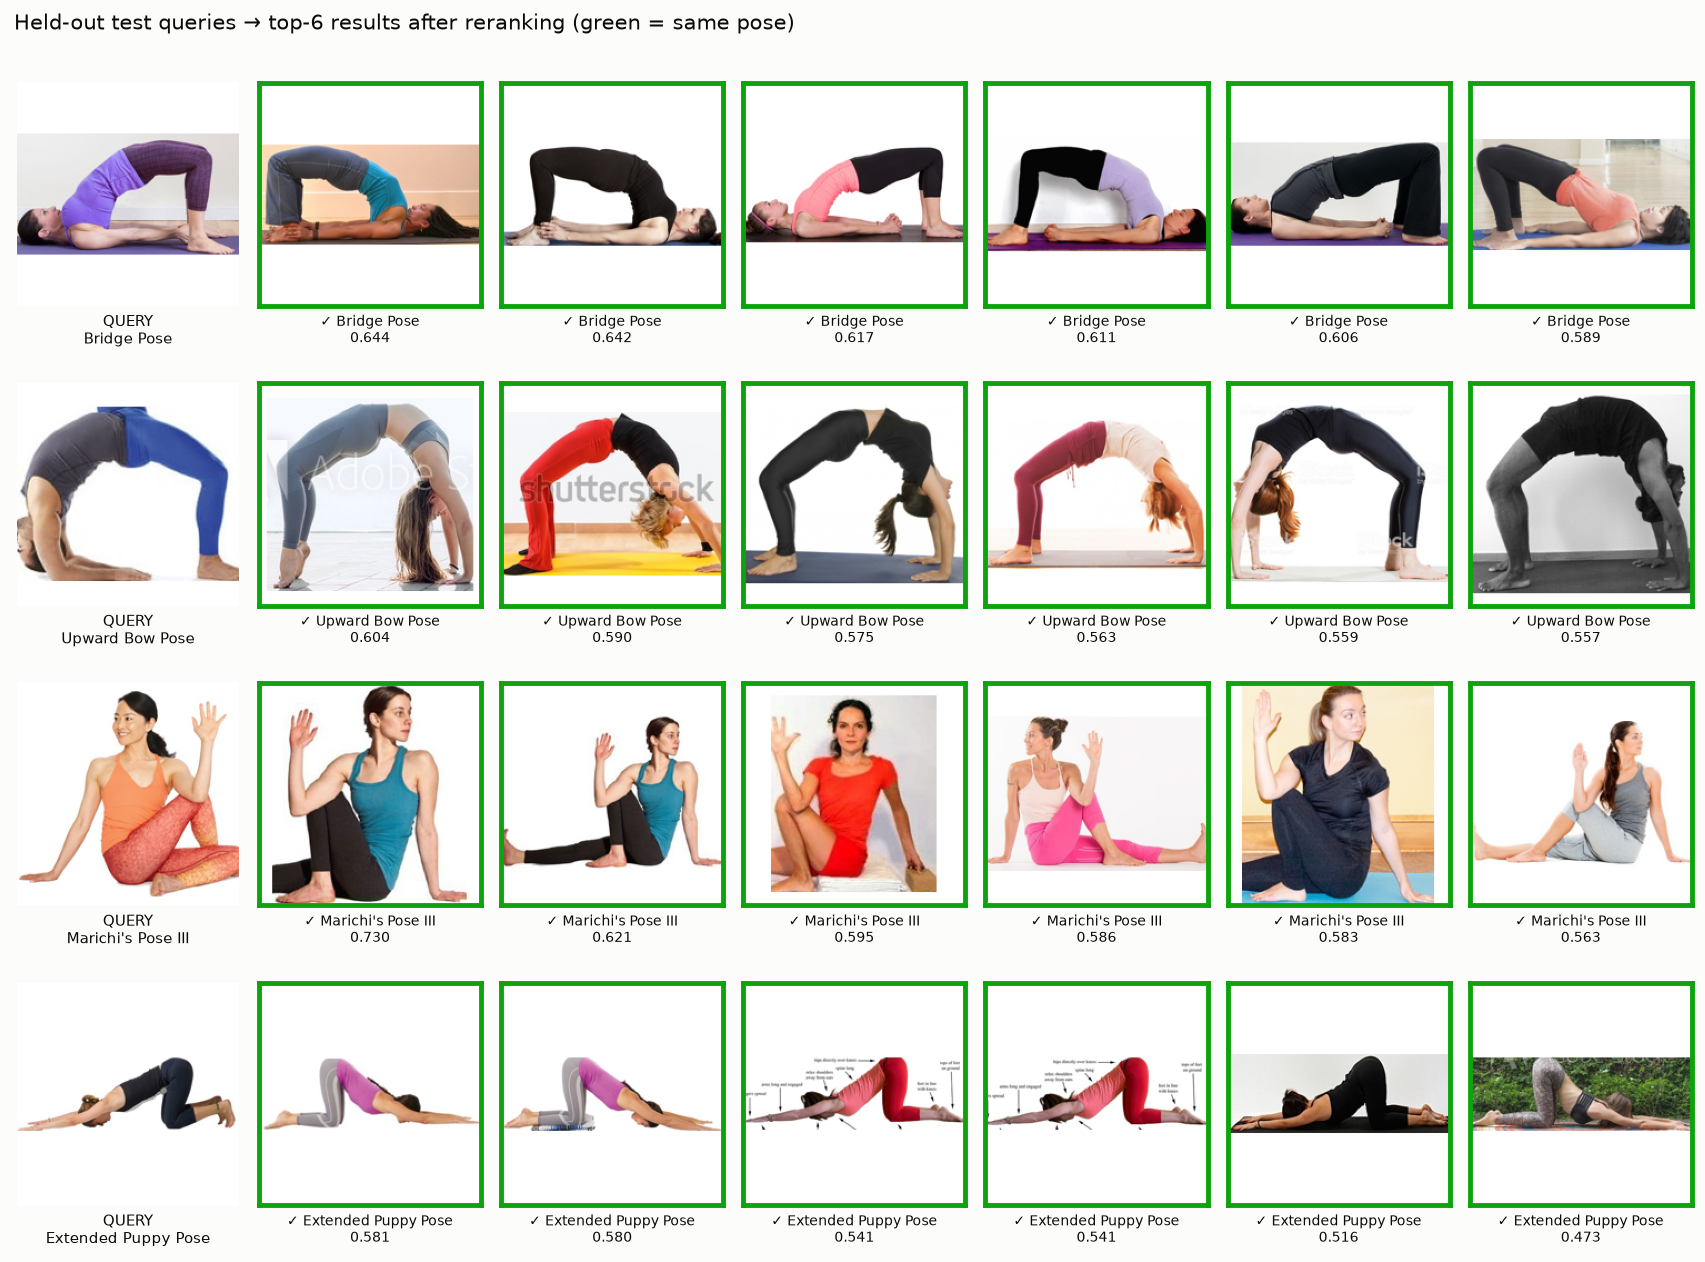

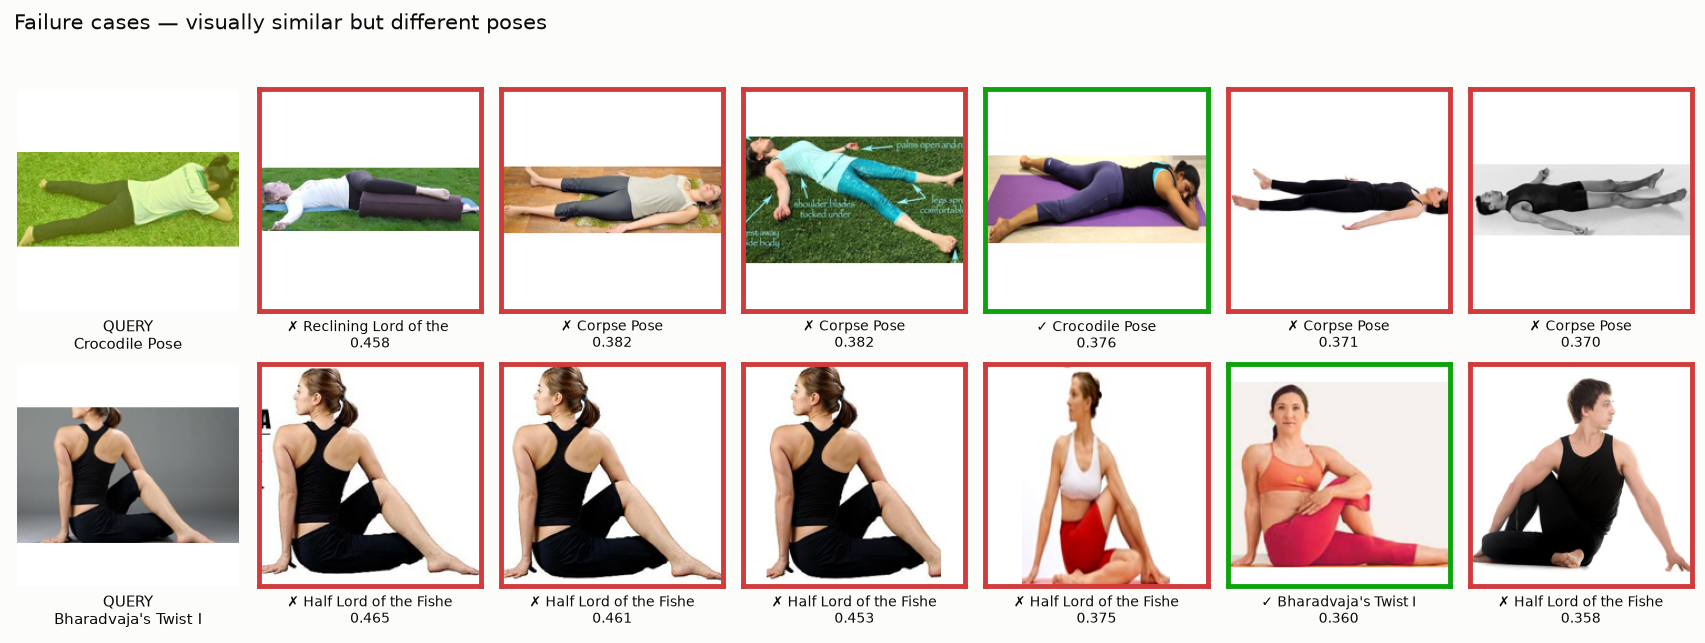

In [9]:
display(Image(FIG / "search_examples.png"))
display(Image(FIG / "search_failures.png"))

### Error analysis

median per-pose P@5 = 0.64;  poses with P@5 ≥ 0.8: 36 / 107


,english,P@5,confused_with,confusion_share
0,One-Legged King Pigeon Pose II,0.133,One-Legged King Pigeon Pose,0.333
1,Scale Pose (another name),0.150,Scale Pose,0.650
2,Hero Pose,0.171,Thunderbolt Pose,0.229
3,Seated Wide-Angle Pose,0.200,Revolved Head-to-Knee Pose,0.178
4,Marichi's Pose I,0.229,Marichi's Pose III,0.457
5,Head-to-Knee Forward Bend,0.233,Seated Forward Bend,0.400
6,Pendant Pose,0.240,Side Crow Pose,0.400
7,Extended High Lunge Pose,0.280,Crescent Lunge Pose,0.280
8,Lotus Pose,0.300,Easy Pose,0.380
9,Formidable Face Pose,0.320,Scorpion Pose,0.400


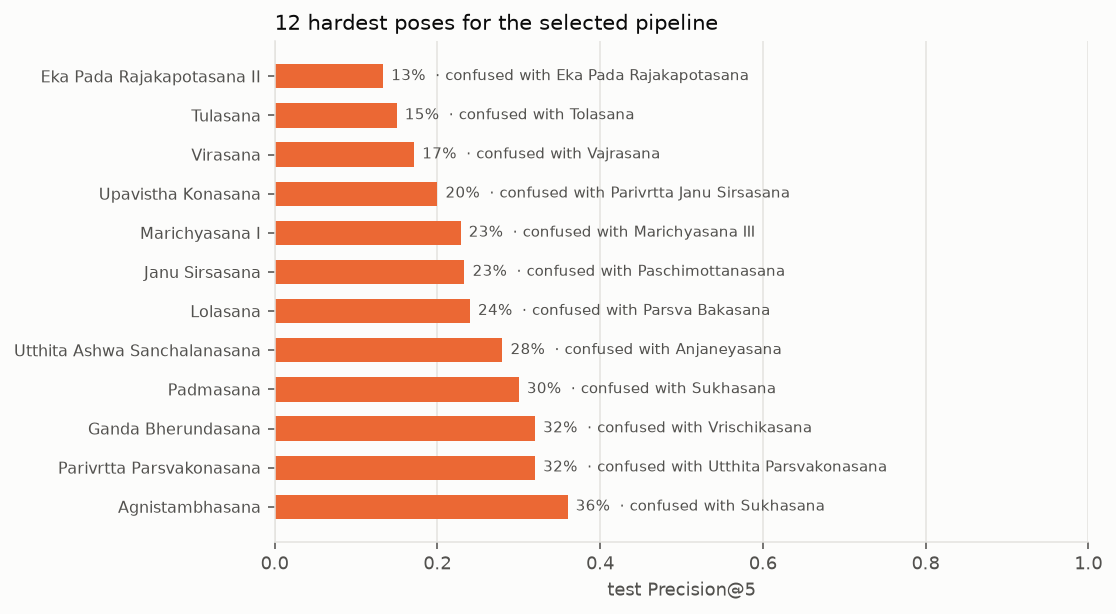

In [10]:
pp = pd.read_csv(METRICS / "per_pose_test.csv")
names = pose_names()
pp["english"] = pp.pose.map(names.english)
pp["confused_with"] = pp.most_confused_with.map(names.english)
print(f"median per-pose P@5 = {pp['P@5'].median():.2f};  poses with P@5 ≥ 0.8: {(pp['P@5'] >= 0.8).sum()} / {len(pp)}")
display(pp[["english", "P@5", "confused_with", "confusion_share"]].head(12))
display(Image(FIG / "search_hardest_poses.png"))

The hardest poses are confused with **near-identical siblings** — Lotus vs. Easy pose, Hero vs.
Thunderbolt, Head-to-Knee vs. Seated Forward Bend — which differ in a detail a global 224-px
descriptor barely sees.

## 6. Text → image search (CLIP)

,prompt,text→image P@1,text→image P@5,text→image P@10,text→image mAP@10,text→image Hit@5,zero-shot acc (test)
0,sanskrit,0.056,0.041,0.037,0.015,0.168,0.057
1,english,0.037,0.036,0.032,0.011,0.168,0.042
2,both,0.112,0.050,0.041,0.021,0.215,0.055
3,ensemble,0.056,0.041,0.036,0.014,0.187,0.051


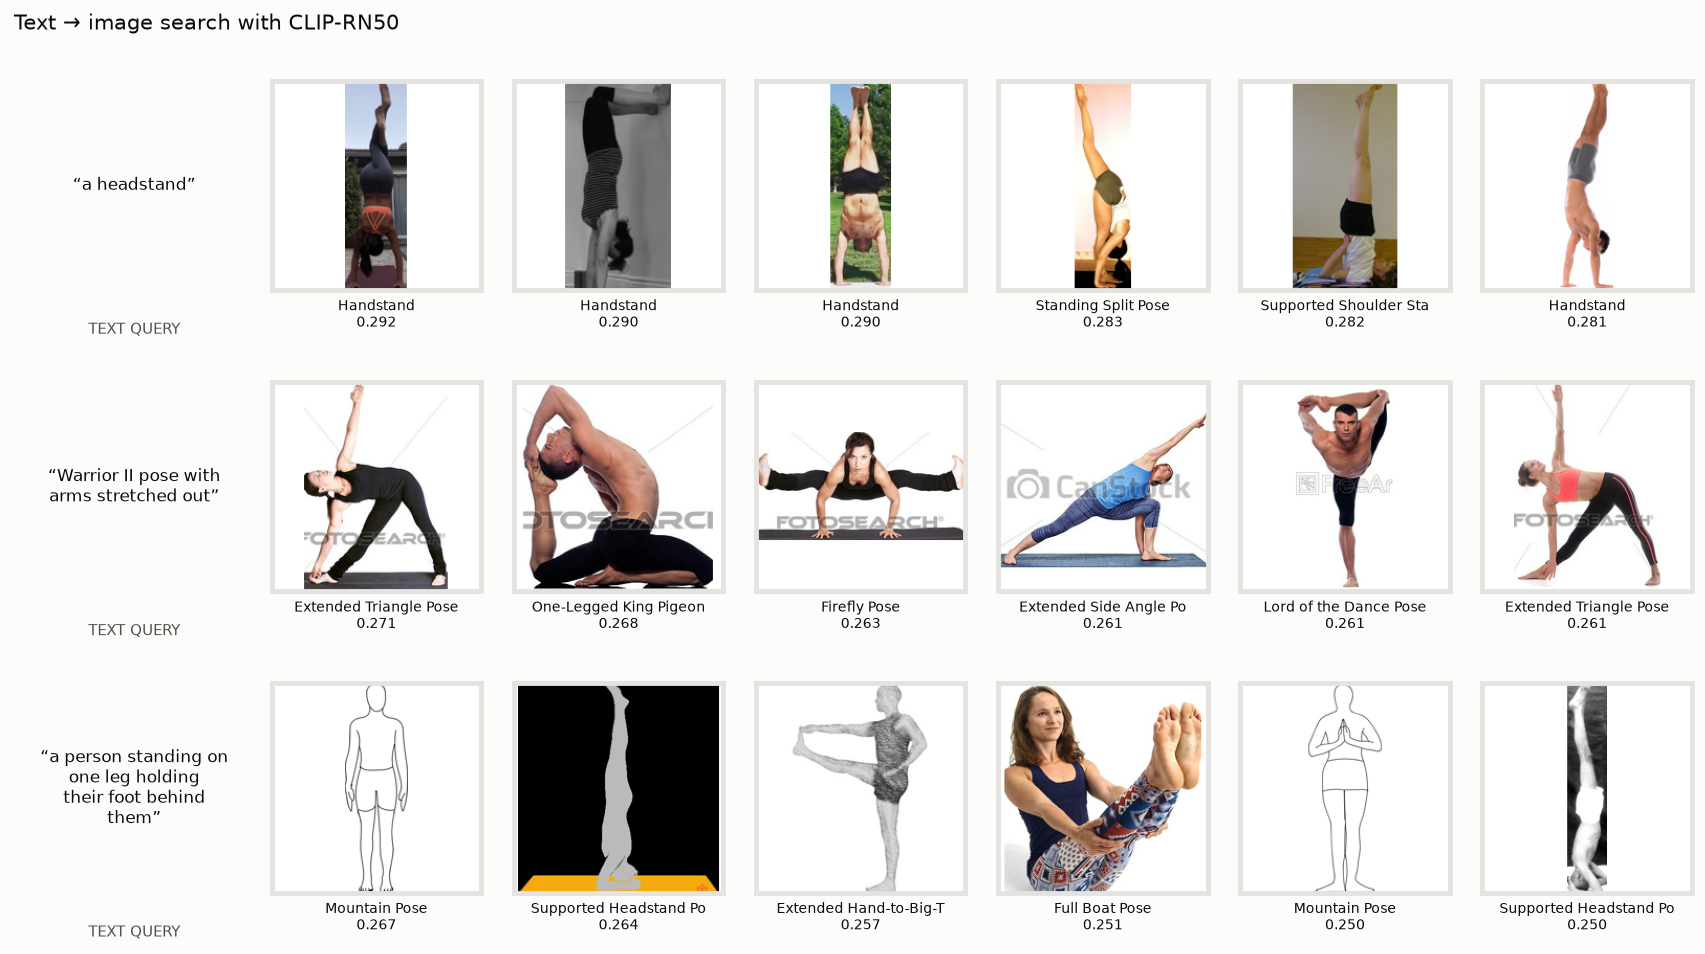

In [11]:
display(pd.read_csv(METRICS / "text_search.csv"))
display(Image(FIG / "search_text_examples.png"))

Distinctive concepts work ("a headstand" returns inversions), fine-grained pose names do not:
zero-shot accuracy over 107 names is ~5 % (chance 0.9 %). Image queries are the primary mode.

## 7. Web application (`streamlit run app.py`)

home.png


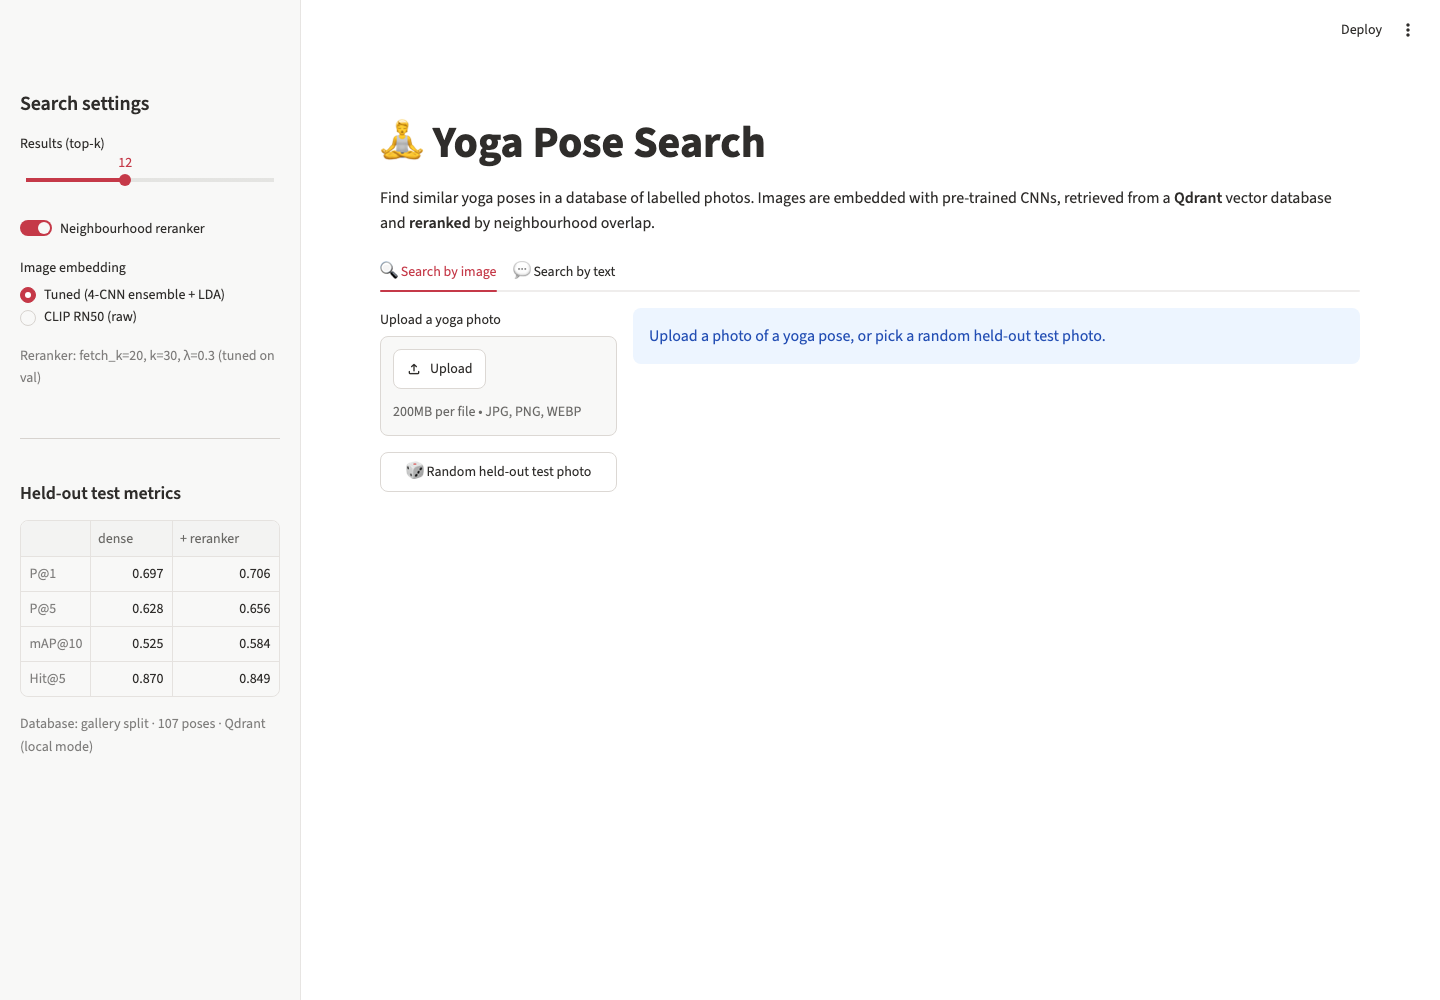

image_upload_results.png


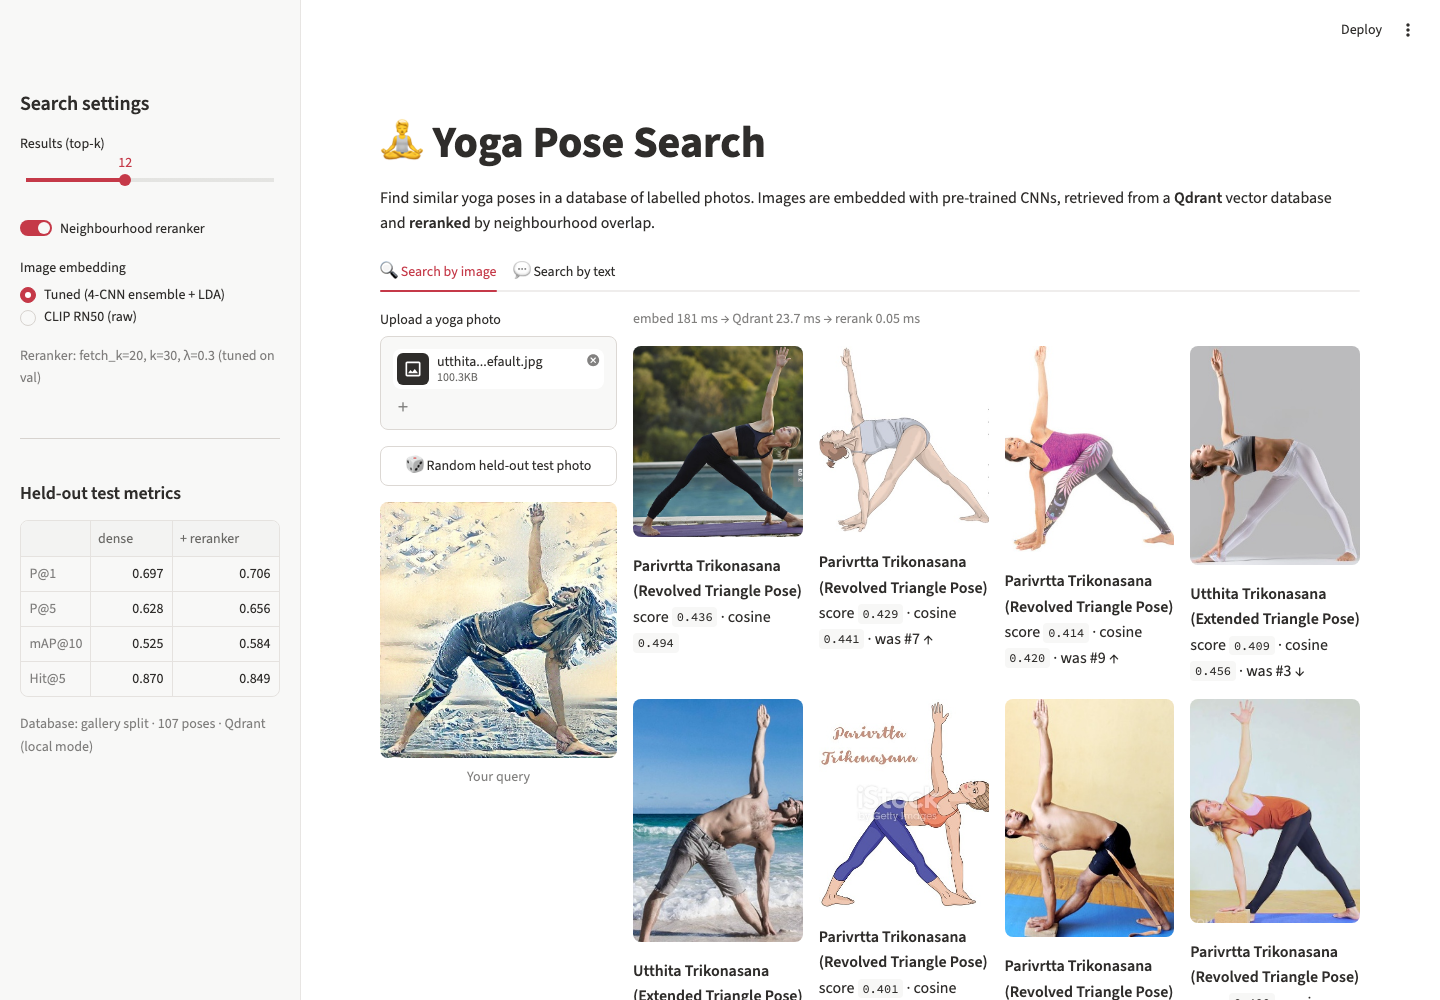

random_test_query.png


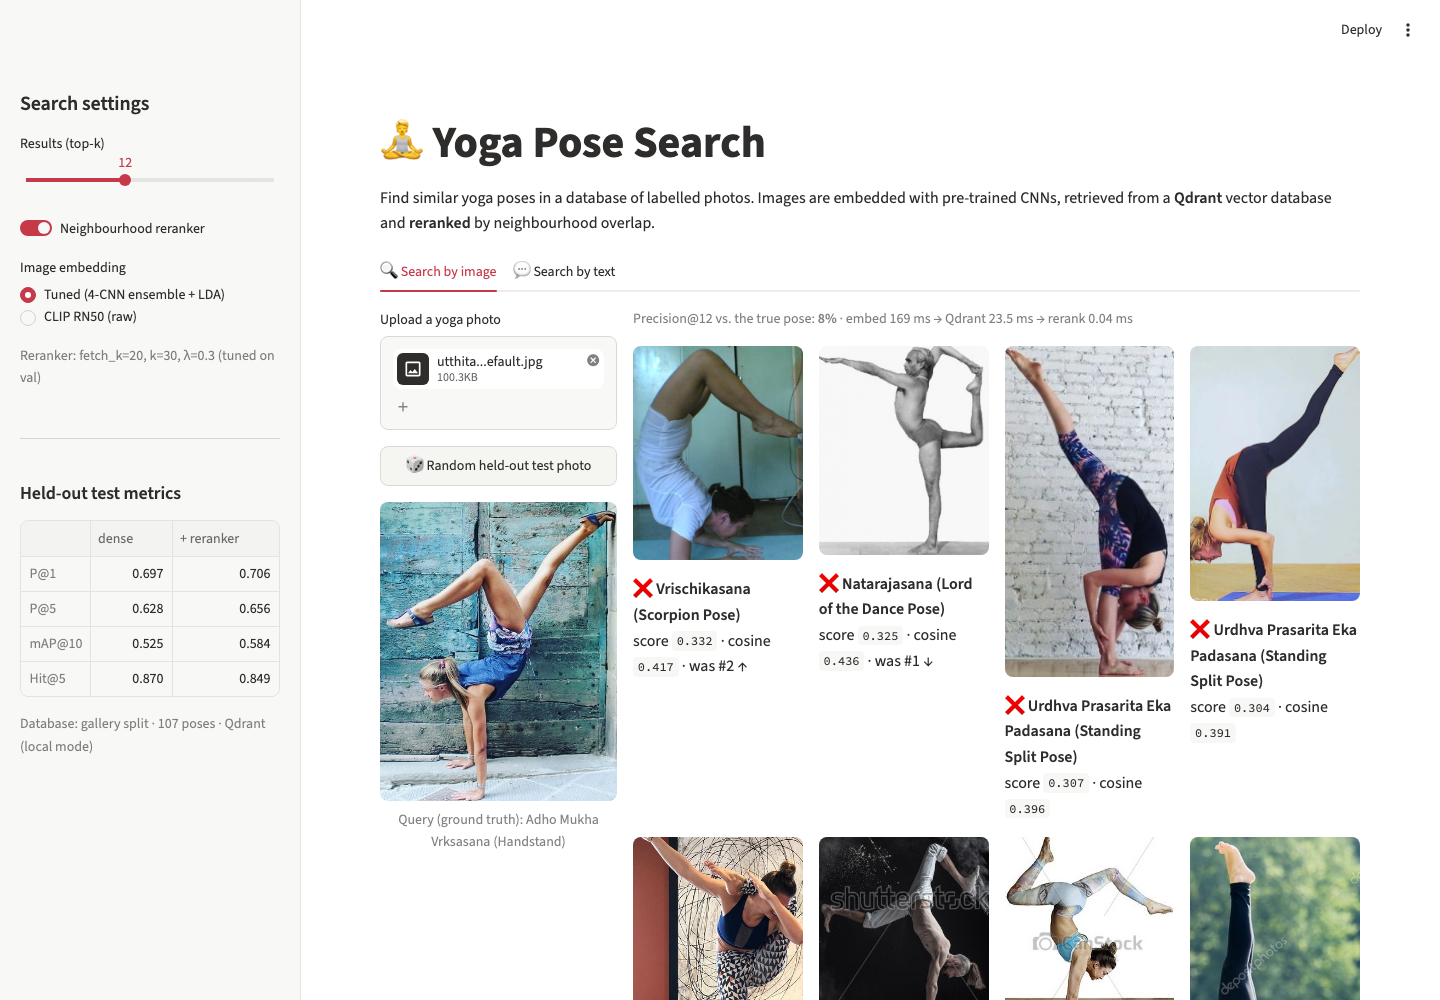

text_search.png


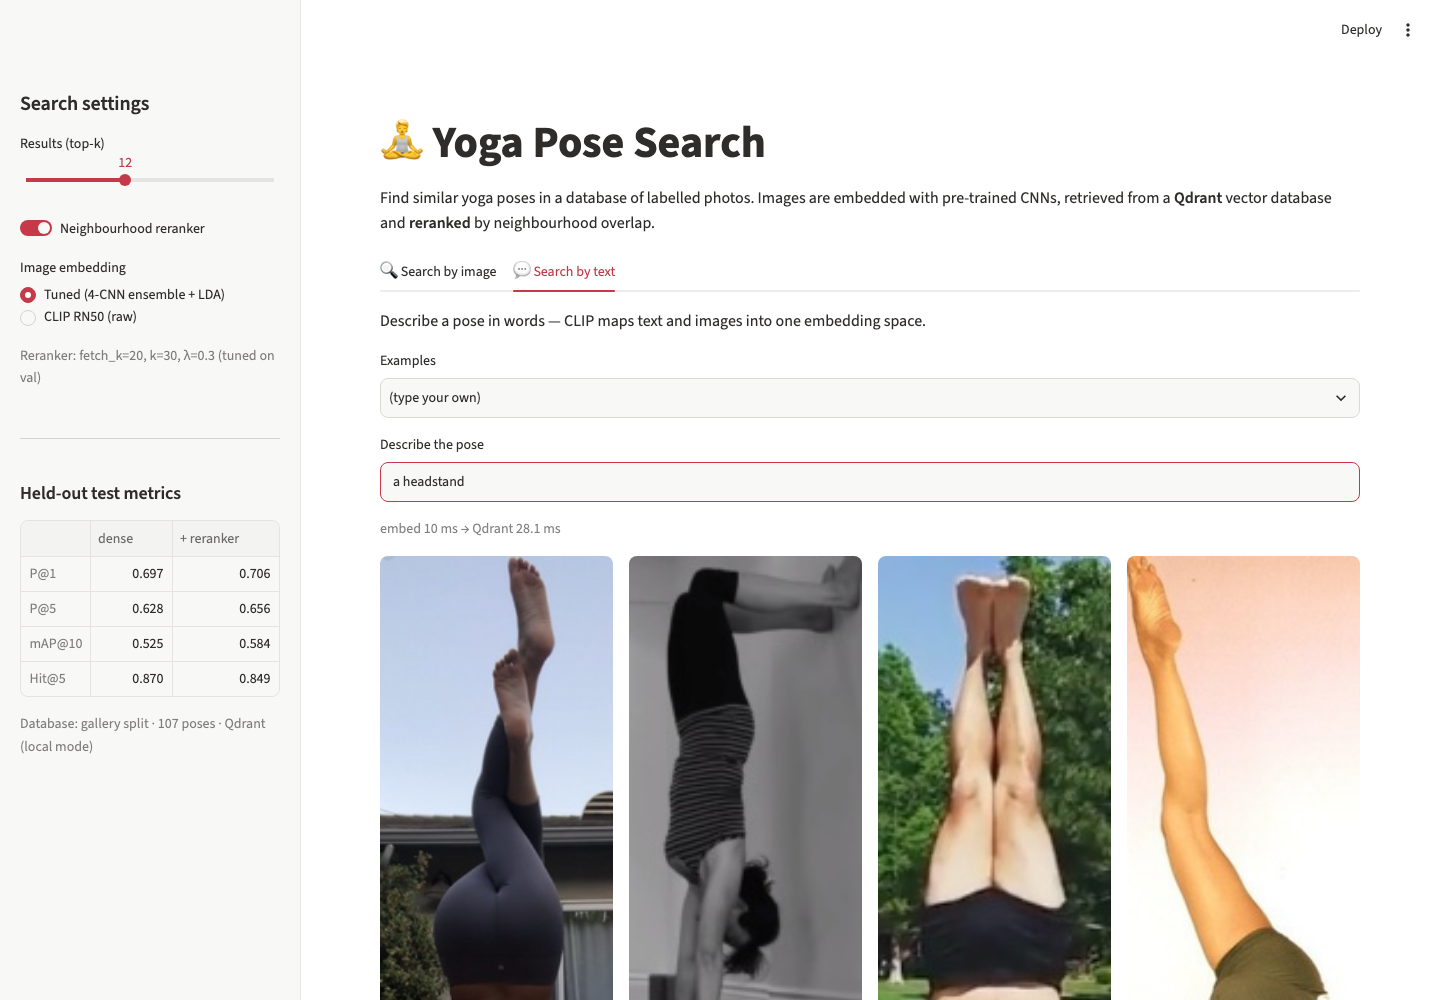

In [12]:
for f in sorted((get_path(config, "output_dir") / "screenshots").glob("*.png")):
    print(f.name)
    display(Image(f, width=900))

## 8. Conclusions

* Frozen CNN embeddings retrieve *photos that look alike*; a 106-d **LDA projection** on the
  labelled gallery (CNNs frozen) is the decisive step, and a 4-CNN ensemble is best.
* A **neighbourhood reranker**, selected with a Hit@5 guardrail, adds +11 % mAP@10 on test
  (0.525 → 0.584) and lifts P@1 and P@5, at a cost of 2 points of Hit@5 and ~0.02 ms per query.
* Next steps: metric-learning fine-tuning of a CNN on the gallery, skeleton-keypoint features for
  sibling poses, and perceptual-hash de-duplication of near-identical photos.